In [1]:
import os

base = r"C:\Users\sawad\Downloads\jeux"

for folder in ["img", "ann"]:
    path = os.path.join(base, folder)
    if os.path.exists(path):
        files = os.listdir(path)
        print(f"✓ {folder}/ → {len(files)} fichiers")
    else:
        print(f"✗ {folder}/ introuvable")

✓ img/ → 351 fichiers
✓ ann/ → 351 fichiers


In [2]:
import json
import os
import re
import numpy as np
from pathlib import Path
from PIL import Image, ImageDraw

def clean_label(label: str) -> str:
    if " = " in label:
        label = label.split(" = ")[0].strip()
    label = label.strip()
    return label

def extract_crop_from_polygon(image, exterior, interior=None, use_mask=True, padding=5):
    img_w, img_h = image.size
    
    xs = [p[0] for p in exterior]
    ys = [p[1] for p in exterior]
    
    x_min = max(0, min(xs) - padding)
    y_min = max(0, min(ys) - padding)
    x_max = min(img_w, max(xs) + padding)
    y_max = min(img_h, max(ys) + padding)
    
    if use_mask:
        mask = Image.new("L", (img_w, img_h), 0)
        draw = ImageDraw.Draw(mask)
        ext_points = [(p[0], p[1]) for p in exterior]
        draw.polygon(ext_points, fill=255)
        if interior:
            for hole in interior:
                hole_points = [(p[0], p[1]) for p in hole]
                draw.polygon(hole_points, fill=0)
        result = Image.new("RGB", image.size, (255, 255, 255))
        result.paste(image, mask=mask)
        crop = result.crop((x_min, y_min, x_max, y_max))
    else:
        crop = image.crop((x_min, y_min, x_max, y_max))
    
    return crop

def process_dataset(img_dir, ann_dir, output_dir, use_mask=True, padding=5):
    img_dir = Path(img_dir)
    ann_dir = Path(ann_dir)
    output_dir = Path(output_dir)
    
    stats = {}
    total_chars = 0
    errors = []
    
    json_files = sorted([f for f in ann_dir.glob("*.json") if "checkpoint" not in str(f)])
    
    if not json_files:
        print(f"Aucun fichier JSON trouvé dans {ann_dir}")
        return
    
    print(f"Trouvé {len(json_files)} fichiers d'annotation")
    print("-" * 50)
    
    for json_file in json_files:
        img_name = json_file.name[:-5]
        
        img_path = None
        for ext in ['', '.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp']:
            candidate = img_dir / f"{img_name}{ext}"
            if candidate.exists():
                img_path = candidate
                break
            base_name = img_name.rsplit('.', 1)[0] if '.' in img_name else img_name
            candidate = img_dir / f"{base_name}{ext}"
            if candidate.exists():
                img_path = candidate
                break
        
        if img_path is None:
            errors.append(f"Image non trouvée pour {json_file.name}")
            continue
        
        try:
            image = Image.open(img_path).convert("RGB")
        except Exception as e:
            errors.append(f"Erreur chargement {img_path}: {e}")
            continue
        
        with open(json_file, "r", encoding="utf-8") as f:
            ann = json.load(f)
        
        objects = ann.get("objects", [])
        print(f"{json_file.name}: {len(objects)} caractères")
        
        for i, obj in enumerate(objects):
            label = clean_label(obj["classTitle"])
            exterior = obj["points"]["exterior"]
            interior = obj["points"].get("interior", [])
            
            label_dir = output_dir / label
            label_dir.mkdir(parents=True, exist_ok=True)
            
            try:
                crop = extract_crop_from_polygon(image, exterior, interior, use_mask=use_mask, padding=padding)
                base = img_path.stem
                crop_filename = f"{base}_char{i:03d}_{label}.png"
                crop_filename = re.sub(r'[<>:"/\\|?*]', '_', crop_filename)
                crop_path = label_dir / crop_filename
                crop.save(crop_path)
                stats[label] = stats.get(label, 0) + 1
                total_chars += 1
            except Exception as e:
                errors.append(f"Erreur {json_file.name} obj {i} ({label}): {e}")
    
    print("\n" + "=" * 50)
    print("RÉSUMÉ DE L'EXTRACTION")
    print("=" * 50)
    print(f"Total caractères extraits: {total_chars}")
    print(f"Nombre de classes: {len(stats)}")
    print(f"\nDistribution:")
    for label, count in sorted(stats.items(), key=lambda x: -x[1]):
        print(f"  {label}: {count}")
    
    if errors:
        print(f"\n⚠ {len(errors)} erreurs:")
        for err in errors:
            print(f"  - {err}")

# Lancement
img_dir = r"C:\Users\sawad\Downloads\jeux\img"
ann_dir = r"C:\Users\sawad\Downloads\jeux\ann"
output_dir = r"C:\Users\sawad\Downloads\jeux\img_info"

process_dataset(img_dir=img_dir, ann_dir=ann_dir, output_dir=output_dir)

Trouvé 351 fichiers d'annotation
--------------------------------------------------
001.jpg.json: 6 caractères
002.jpg.json: 8 caractères
003.png.json: 7 caractères
004.png.json: 6 caractères
005.png.json: 6 caractères
006.png.json: 6 caractères
007.png.json: 10 caractères
008.png.json: 7 caractères
009.png.json: 7 caractères
010.png.json: 6 caractères
011.png.json: 6 caractères
012.png.json: 6 caractères
013.png.json: 6 caractères
014.png.json: 5 caractères
015.png.json: 5 caractères
016.png.json: 5 caractères
017.png.json: 5 caractères
018.png.json: 6 caractères
019.png.json: 5 caractères
020.png.json: 3 caractères
021.png.json: 4 caractères
022.png.json: 5 caractères
023.png.json: 5 caractères
024.png.json: 5 caractères
025.png.json: 7 caractères
026.png.json: 6 caractères
027.png.json: 6 caractères
028.png.json: 6 caractères
029.png.json: 5 caractères
030.png.json: 5 caractères
031.png.json: 6 caractères
032.png.json: 6 caractères
033.png.json: 7 caractères
034.png.json: 7 caractèr

In [3]:
import shutil
import json
from pathlib import Path

def clean_dataset(characters_dir):
    characters_dir = Path(characters_dir)

    # Fusionner C et C moon-shaped sigma → Ϲ
    target = characters_dir / "Ϲ"
    target.mkdir(exist_ok=True)

    for old_name in ["C", "C moon-shaped sigma"]:
        old_dir = characters_dir / old_name
        if old_dir.exists():
            for f in old_dir.iterdir():
                if f.is_file():
                    shutil.move(str(f), str(target / f.name))
            old_dir.rmdir()
            print(f"✓ Fusionné '{old_name}' → 'Ϲ'")

    # Supprimer les classes invalides
    for label in ["Character", "И", "R"]:
        label_dir = characters_dir / label
        if label_dir.exists():
            count = len(list(label_dir.iterdir()))
            shutil.rmtree(label_dir)
            print(f"✓ Supprimé '{label}' ({count} images)")

    # Stats finales
    stats = {}
    total = 0

    for label_dir in sorted(characters_dir.iterdir()):
        if label_dir.is_dir() and label_dir.name != ".ipynb_checkpoints":
            count = len([f for f in label_dir.iterdir() if f.is_file() and f.suffix == '.png'])
            if count > 0:
                stats[label_dir.name] = count
                total += count

    stats_file = characters_dir / "stats.json"
    with open(stats_file, "w", encoding="utf-8") as f:
        json.dump({
            "total_characters": total,
            "num_classes": len(stats),
            "distribution": dict(sorted(stats.items(), key=lambda x: -x[1]))
        }, f, ensure_ascii=False, indent=2)

    print("\n" + "=" * 50)
    print("DATASET APRÈS NETTOYAGE")
    print("=" * 50)
    print(f"Total caractères: {total}")
    print(f"Nombre de classes: {len(stats)}")
    print(f"\nDistribution:")
    for label, count in sorted(stats.items(), key=lambda x: -x[1]):
        print(f"  {label}: {count}")

characters_dir = r"C:\Users\sawad\Downloads\jeux\img_info"
clean_dataset(characters_dir)

✓ Fusionné 'C' → 'Ϲ'
✓ Fusionné 'C moon-shaped sigma' → 'Ϲ'
✓ Supprimé 'Character' (3 images)
✓ Supprimé 'И' (8 images)
✓ Supprimé 'R' (1 images)

DATASET APRÈS NETTOYAGE
Total caractères: 2143
Nombre de classes: 26

Distribution:
  Α: 211
  Ι: 201
  V: 196
  Ο: 160
  Ρ: 155
  Ε: 134
  ligature OU: 118
  Τ: 113
  Ν: 93
  ω: 88
  Π: 84
  Ϲ: 79
  Κ: 70
  Λ: 68
  Μ: 59
  Θ: 53
  Δ: 50
  Γ: 43
  Η: 38
  Χ: 36
  Β: 35
  Φ: 24
  Σ: 19
  Ζ: 10
  Ψ: 4
  Ξ: 2


In [4]:
import shutil
import json
import random
from pathlib import Path

def split_dataset(characters_dir, output_dir, test_ratio=0.2, seed=42):
    characters_dir = Path(characters_dir)
    output_dir = Path(output_dir)
    random.seed(seed)

    train_dir = output_dir / "train"
    test_dir = output_dir / "test"

    stats_train = {}
    stats_test = {}

    for label_dir in sorted(characters_dir.iterdir()):
        if not label_dir.is_dir() or label_dir.name in [".ipynb_checkpoints", "stats.json"]:
            continue

        label = label_dir.name
        images = [f for f in label_dir.iterdir() if f.is_file() and f.suffix == '.png']

        if len(images) == 0:
            continue

        random.shuffle(images)
        n_test = max(1, int(len(images) * test_ratio))

        test_images = images[:n_test]
        train_images = images[n_test:]

        train_label_dir = train_dir / label
        train_label_dir.mkdir(parents=True, exist_ok=True)
        for img in train_images:
            shutil.copy2(str(img), str(train_label_dir / img.name))

        test_label_dir = test_dir / label
        test_label_dir.mkdir(parents=True, exist_ok=True)
        for img in test_images:
            shutil.copy2(str(img), str(test_label_dir / img.name))

        stats_train[label] = len(train_images)
        stats_test[label] = len(test_images)

        print(f"  {label}: {len(train_images)} train / {len(test_images)} test")

    total_train = sum(stats_train.values())
    total_test = sum(stats_test.values())

    print("\n" + "=" * 50)
    print("RÉSUMÉ DU SPLIT")
    print("=" * 50)
    print(f"Train: {total_train} images ({total_train/(total_train+total_test)*100:.1f}%)")
    print(f"Test:  {total_test} images ({total_test/(total_train+total_test)*100:.1f}%)")
    print(f"Classes: {len(stats_train)}")

characters_dir = r"C:\Users\sawad\Downloads\jeux\img_info"
output_dir = r"C:\Users\sawad\Downloads\jeux\split"

split_dataset(characters_dir, output_dir, test_ratio=0.2)

  ligature OU: 95 train / 23 test
  V: 157 train / 39 test
  Α: 169 train / 42 test
  Β: 28 train / 7 test
  Γ: 35 train / 8 test
  Δ: 40 train / 10 test
  Ε: 108 train / 26 test
  Ζ: 8 train / 2 test
  Η: 31 train / 7 test
  Θ: 43 train / 10 test
  Ι: 161 train / 40 test
  Κ: 56 train / 14 test
  Λ: 55 train / 13 test
  Μ: 48 train / 11 test
  Ν: 75 train / 18 test
  Ξ: 1 train / 1 test
  Ο: 128 train / 32 test
  Π: 68 train / 16 test
  Ρ: 124 train / 31 test
  Σ: 16 train / 3 test
  Τ: 91 train / 22 test
  Φ: 20 train / 4 test
  Χ: 29 train / 7 test
  Ψ: 3 train / 1 test
  ω: 71 train / 17 test
  Ϲ: 64 train / 15 test

RÉSUMÉ DU SPLIT
Train: 1724 images (80.4%)
Test:  419 images (19.6%)
Classes: 26


In [5]:
from torchvision import datasets, transforms

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(root=f"{SPLIT_DIR}/train", transform=train_transform)
test_dataset = datasets.ImageFolder(root=f"{SPLIT_DIR}/test", transform=test_transform)

print(f"Classes trouvées: {train_dataset.classes}")
print(f"Nombre de classes: {len(train_dataset.classes)}")
print(f"Nombre d'images train: {len(train_dataset)}")
print(f"Nombre d'images test: {len(test_dataset)}")

Classes trouvées: ['C_moon-shaped_sigma', 'R', 'V', 'V___Y', 'ligature OU', 'ligature_OU', 'Α', 'Β', 'Γ', 'Δ', 'Ε', 'Ζ', 'Η', 'Θ', 'Ι', 'Κ', 'Λ', 'Μ', 'Ν', 'Ξ', 'Ο', 'Π', 'Ρ', 'Ρ___rho', 'Σ', 'Τ', 'Φ', 'Χ', 'Ψ', 'ω', 'Ϲ', 'И___N']
Nombre de classes: 32
Nombre d'images train: 3751
Nombre d'images test: 1200


In [6]:
import os
from torchvision import datasets, transforms

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"

# Vérifie d'abord ce qui est vraiment dans ce dossier
print("Contenu de split/train :")
for cls in sorted(os.listdir(os.path.join(SPLIT_DIR, "train"))):
    n = len(os.listdir(os.path.join(SPLIT_DIR, "train", cls)))
    print(f"  {cls}: {n} images")

Contenu de split/train :
  C_moon-shaped_sigma: 28 images
  R: 1 images
  V: 201 images
  V___Y: 148 images
  ligature OU: 114 images
  ligature_OU: 94 images
  Α: 370 images
  Β: 63 images
  Γ: 75 images
  Δ: 88 images
  Ε: 236 images
  Ζ: 18 images
  Η: 70 images
  Θ: 96 images
  Ι: 353 images
  Κ: 121 images
  Λ: 117 images
  Μ: 102 images
  Ν: 159 images
  Ξ: 4 images
  Ο: 281 images
  Π: 149 images
  Ρ: 146 images
  Ρ___rho: 124 images
  Σ: 16 images
  Τ: 199 images
  Φ: 41 images
  Χ: 61 images
  Ψ: 7 images
  ω: 154 images
  Ϲ: 109 images
  И___N: 6 images


In [7]:
import shutil
import os

split_dir = r"C:\Users\sawad\Downloads\jeux\split"

# Supprimer l'ancien split
if os.path.exists(split_dir):
    shutil.rmtree(split_dir)
    print("✓ Ancien split supprimé")

# Relancer le split propre
characters_dir = r"C:\Users\sawad\Downloads\jeux\img_info"

split_dataset(characters_dir, split_dir, test_ratio=0.2)

✓ Ancien split supprimé
  ligature OU: 95 train / 23 test
  V: 157 train / 39 test
  Α: 169 train / 42 test
  Β: 28 train / 7 test
  Γ: 35 train / 8 test
  Δ: 40 train / 10 test
  Ε: 108 train / 26 test
  Ζ: 8 train / 2 test
  Η: 31 train / 7 test
  Θ: 43 train / 10 test
  Ι: 161 train / 40 test
  Κ: 56 train / 14 test
  Λ: 55 train / 13 test
  Μ: 48 train / 11 test
  Ν: 75 train / 18 test
  Ξ: 1 train / 1 test
  Ο: 128 train / 32 test
  Π: 68 train / 16 test
  Ρ: 124 train / 31 test
  Σ: 16 train / 3 test
  Τ: 91 train / 22 test
  Φ: 20 train / 4 test
  Χ: 29 train / 7 test
  Ψ: 3 train / 1 test
  ω: 71 train / 17 test
  Ϲ: 64 train / 15 test

RÉSUMÉ DU SPLIT
Train: 1724 images (80.4%)
Test:  419 images (19.6%)
Classes: 26


In [8]:
import os
from torchvision import datasets, transforms

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "train"), transform=train_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform)

print(f"Classes trouvées: {train_dataset.classes}")
print(f"Nombre de classes: {len(train_dataset.classes)}")
print(f"Nombre d'images train: {len(train_dataset)}")
print(f"Nombre d'images test: {len(test_dataset)}")

Classes trouvées: ['V', 'ligature OU', 'Α', 'Β', 'Γ', 'Δ', 'Ε', 'Ζ', 'Η', 'Θ', 'Ι', 'Κ', 'Λ', 'Μ', 'Ν', 'Ξ', 'Ο', 'Π', 'Ρ', 'Σ', 'Τ', 'Φ', 'Χ', 'Ψ', 'ω', 'Ϲ']
Nombre de classes: 26
Nombre d'images train: 1724
Nombre d'images test: 419


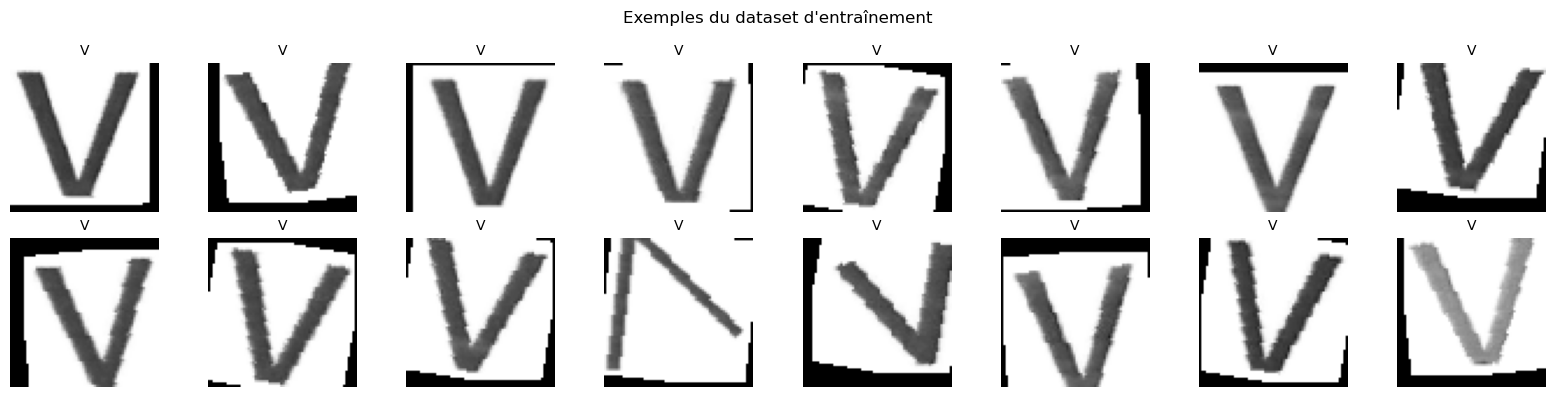

In [10]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(16):
    img, label = train_dataset[i]
    ax = axes[i // 8][i % 8]
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(class_names[label], fontsize=10)
    ax.axis('off')
plt.suptitle("Exemples du dataset d'entraînement")
plt.tight_layout()
plt.show()


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import os
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"
IMG_SIZE = 64
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

train_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "train"), transform=train_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_dataset.classes
num_classes = len(class_names)

print(f"Classes ({num_classes}): {class_names}")
print(f"Train: {len(train_dataset)} images")
print(f"Test:  {len(test_dataset)} images")

# Modèle
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SimpleCNN(num_classes).to(device)

NUM_EPOCHS = 50
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
best_test_acc = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    model.eval()
    test_loss, test_correct, test_total = 0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            test_correct += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_loss /= test_total
    test_acc = test_correct / test_total
    scheduler.step(test_loss)

    if test_acc > best_test_acc:
        best_test_acc = test_acc
        torch.save(model.state_dict(), "best_cnn_model.pth")

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}")

print(f"\nMeilleure accuracy test: {best_test_acc:.4f}")

Device: cpu
Classes (26): ['V', 'ligature OU', 'Α', 'Β', 'Γ', 'Δ', 'Ε', 'Ζ', 'Η', 'Θ', 'Ι', 'Κ', 'Λ', 'Μ', 'Ν', 'Ξ', 'Ο', 'Π', 'Ρ', 'Σ', 'Τ', 'Φ', 'Χ', 'Ψ', 'ω', 'Ϲ']
Train: 1724 images
Test:  419 images
Epoch [5/50] Train Loss: 0.8930 Acc: 0.7541 | Test Loss: 0.4327 Acc: 0.9117
Epoch [10/50] Train Loss: 0.7441 Acc: 0.7616 | Test Loss: 0.4898 Acc: 0.9141
Epoch [15/50] Train Loss: 0.6120 Acc: 0.8132 | Test Loss: 0.4727 Acc: 0.9189
Epoch [20/50] Train Loss: 0.5112 Acc: 0.8585 | Test Loss: 0.4304 Acc: 0.9379
Epoch [25/50] Train Loss: 0.4487 Acc: 0.8648 | Test Loss: 0.4602 Acc: 0.9308
Epoch [30/50] Train Loss: 0.4326 Acc: 0.8747 | Test Loss: 0.4569 Acc: 0.9379
Epoch [35/50] Train Loss: 0.4206 Acc: 0.8863 | Test Loss: 0.4603 Acc: 0.9379
Epoch [40/50] Train Loss: 0.3905 Acc: 0.8794 | Test Loss: 0.4571 Acc: 0.9403
Epoch [45/50] Train Loss: 0.3853 Acc: 0.8968 | Test Loss: 0.4580 Acc: 0.9379
Epoch [50/50] Train Loss: 0.3738 Acc: 0.8915 | Test Loss: 0.4562 Acc: 0.9403

Meilleure accuracy test: 0

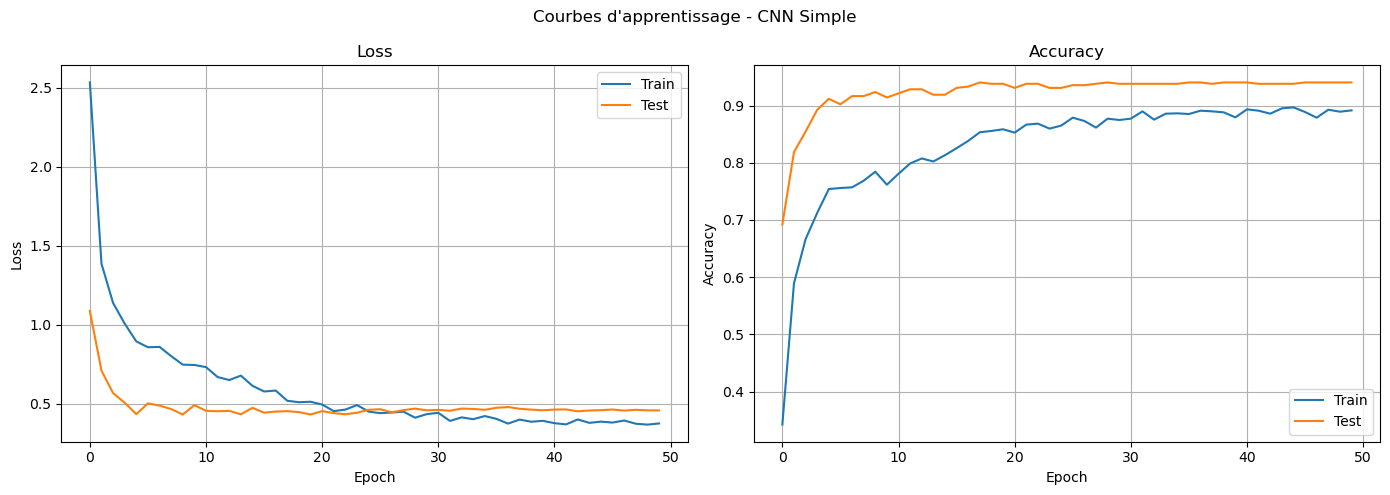

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["test_loss"], label="Test")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(history["train_acc"], label="Train")
ax2.plot(history["test_acc"], label="Test")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.suptitle("Courbes d'apprentissage - CNN Simple")
plt.tight_layout()
plt.show()

In [12]:
model.load_state_dict(torch.load("best_cnn_model.pth"))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())


print("=" * 60)
print("RAPPORT DE CLASSIFICATION - CNN SIMPLE")
print("=" * 60)
print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

# Accuracy globale
acc = accuracy_score(all_labels, all_preds)
print(f"Accuracy globale: {acc:.4f} ({acc*100:.1f}%)")

RAPPORT DE CLASSIFICATION - CNN SIMPLE
              precision    recall  f1-score   support

           V       0.97      0.92      0.95        39
 ligature OU       0.88      1.00      0.94        23
           Α       0.87      0.95      0.91        42
           Β       1.00      1.00      1.00         7
           Γ       1.00      0.88      0.93         8
           Δ       0.90      0.90      0.90        10
           Ε       0.96      0.92      0.94        26
           Ζ       0.67      1.00      0.80         2
           Η       1.00      1.00      1.00         7
           Θ       1.00      1.00      1.00        10
           Ι       1.00      0.95      0.97        40
           Κ       1.00      0.71      0.83        14
           Λ       0.75      0.92      0.83        13
           Μ       0.92      1.00      0.96        11
           Ν       0.94      0.94      0.94        18
           Ξ       0.00      0.00      0.00         1
           Ο       1.00      1.00      1.0

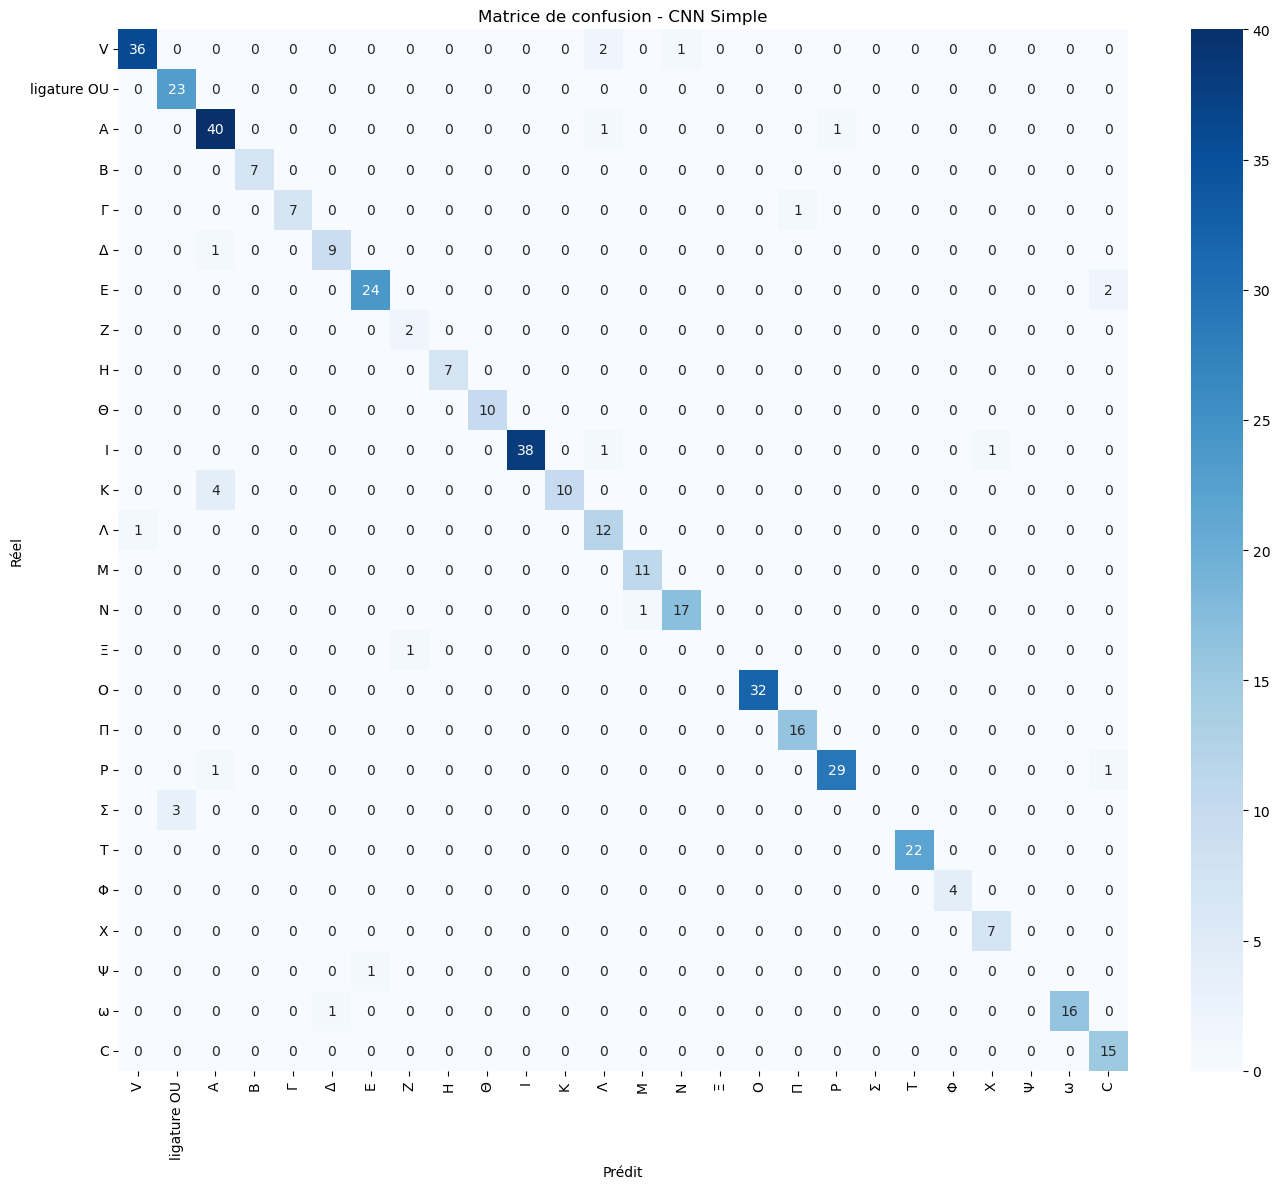


Résultats sauvegardés dans results_cnn.json


In [13]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title('Matrice de confusion - CNN Simple')
plt.tight_layout()
plt.show()

# Sauvegarder les résultats
results = {
    "model": "CNN Simple",
    "best_test_accuracy": best_test_acc,
    "final_test_accuracy": acc,
    "num_classes": num_classes,
    "num_epochs": NUM_EPOCHS,
    "classification_report": classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
}

with open("results_cnn.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("\nRésultats sauvegardés dans results_cnn.json")

In [14]:
from torchvision import models

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"
IMG_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "train"), transform=train_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_dataset.classes
num_classes = len(class_names)

# ResNet18 avec transfer learning
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
)

for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")

NUM_EPOCHS = 40
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

history_resnet = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
best_test_acc_resnet = 0.0

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    model.eval()
    test_loss, test_correct, test_total = 0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            test_correct += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_loss /= test_total
    test_acc = test_correct / test_total
    scheduler.step(test_loss)

    if test_acc > best_test_acc_resnet:
        best_test_acc_resnet = test_acc
        torch.save(model.state_dict(), "best_resnet_model.pth")

    history_resnet["train_loss"].append(train_loss)
    history_resnet["train_acc"].append(train_acc)
    history_resnet["test_loss"].append(test_loss)
    history_resnet["test_acc"].append(test_acc)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}")

print(f"\nMeilleure accuracy test ResNet: {best_test_acc_resnet:.4f}")

Total params: 11,314,522
Trainable params: 8,531,738 (75.4%)
Epoch [5/40] Train Loss: 0.2671 Acc: 0.9374 | Test Loss: 0.2881 Acc: 0.9523
Epoch [10/40] Train Loss: 0.2154 Acc: 0.9484 | Test Loss: 0.3638 Acc: 0.9475
Epoch [15/40] Train Loss: 0.1178 Acc: 0.9710 | Test Loss: 0.3830 Acc: 0.9570
Epoch [20/40] Train Loss: 0.0968 Acc: 0.9710 | Test Loss: 0.4168 Acc: 0.9570
Epoch [25/40] Train Loss: 0.0903 Acc: 0.9745 | Test Loss: 0.4084 Acc: 0.9594
Epoch [30/40] Train Loss: 0.0765 Acc: 0.9762 | Test Loss: 0.4161 Acc: 0.9618
Epoch [35/40] Train Loss: 0.0815 Acc: 0.9739 | Test Loss: 0.3955 Acc: 0.9666
Epoch [40/40] Train Loss: 0.0588 Acc: 0.9791 | Test Loss: 0.4043 Acc: 0.9666

Meilleure accuracy test ResNet: 0.9666


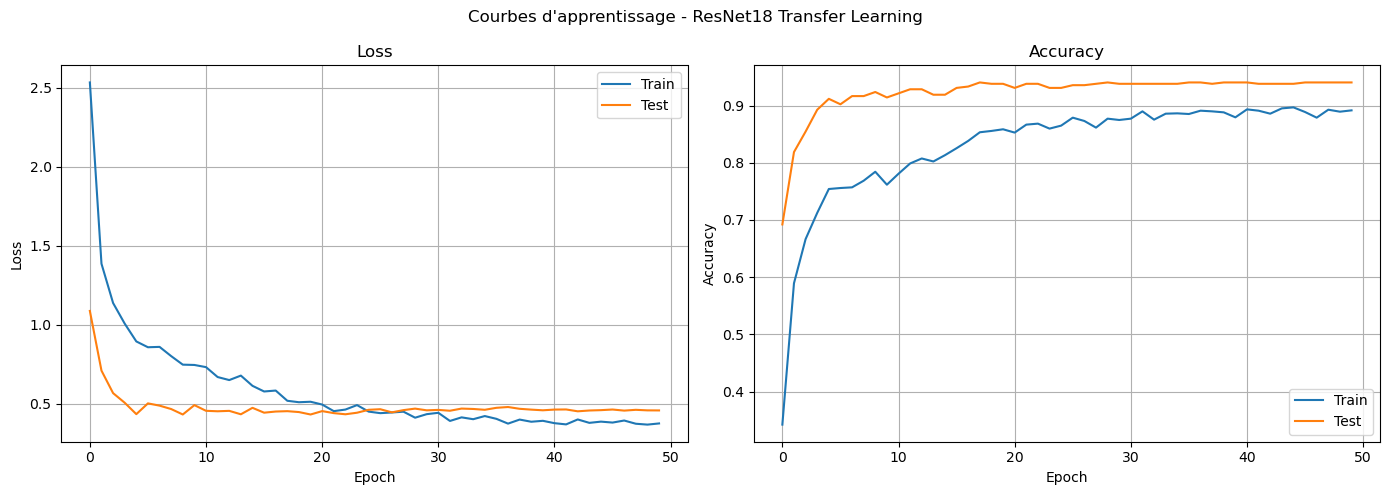

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["test_loss"], label="Test")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(history["train_acc"], label="Train")
ax2.plot(history["test_acc"], label="Test")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.suptitle("Courbes d'apprentissage - ResNet18 Transfer Learning")
plt.tight_layout()
plt.show()

In [16]:
model.load_state_dict(torch.load("best_resnet_model.pth"))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("=" * 60)
print("RAPPORT DE CLASSIFICATION - RESNET18 TRANSFER LEARNING")
print("=" * 60)
print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

acc = accuracy_score(all_labels, all_preds)
print(f"Accuracy globale: {acc:.4f} ({acc*100:.1f}%)")

RAPPORT DE CLASSIFICATION - RESNET18 TRANSFER LEARNING
              precision    recall  f1-score   support

           V       0.97      0.92      0.95        39
 ligature OU       0.88      1.00      0.94        23
           Α       0.98      0.98      0.98        42
           Β       1.00      1.00      1.00         7
           Γ       1.00      1.00      1.00         8
           Δ       0.90      0.90      0.90        10
           Ε       0.96      0.96      0.96        26
           Ζ       1.00      1.00      1.00         2
           Η       1.00      1.00      1.00         7
           Θ       1.00      1.00      1.00        10
           Ι       1.00      1.00      1.00        40
           Κ       0.93      0.93      0.93        14
           Λ       0.75      0.92      0.83        13
           Μ       1.00      1.00      1.00        11
           Ν       0.95      1.00      0.97        18
           Ξ       1.00      1.00      1.00         1
           Ο       1.00   

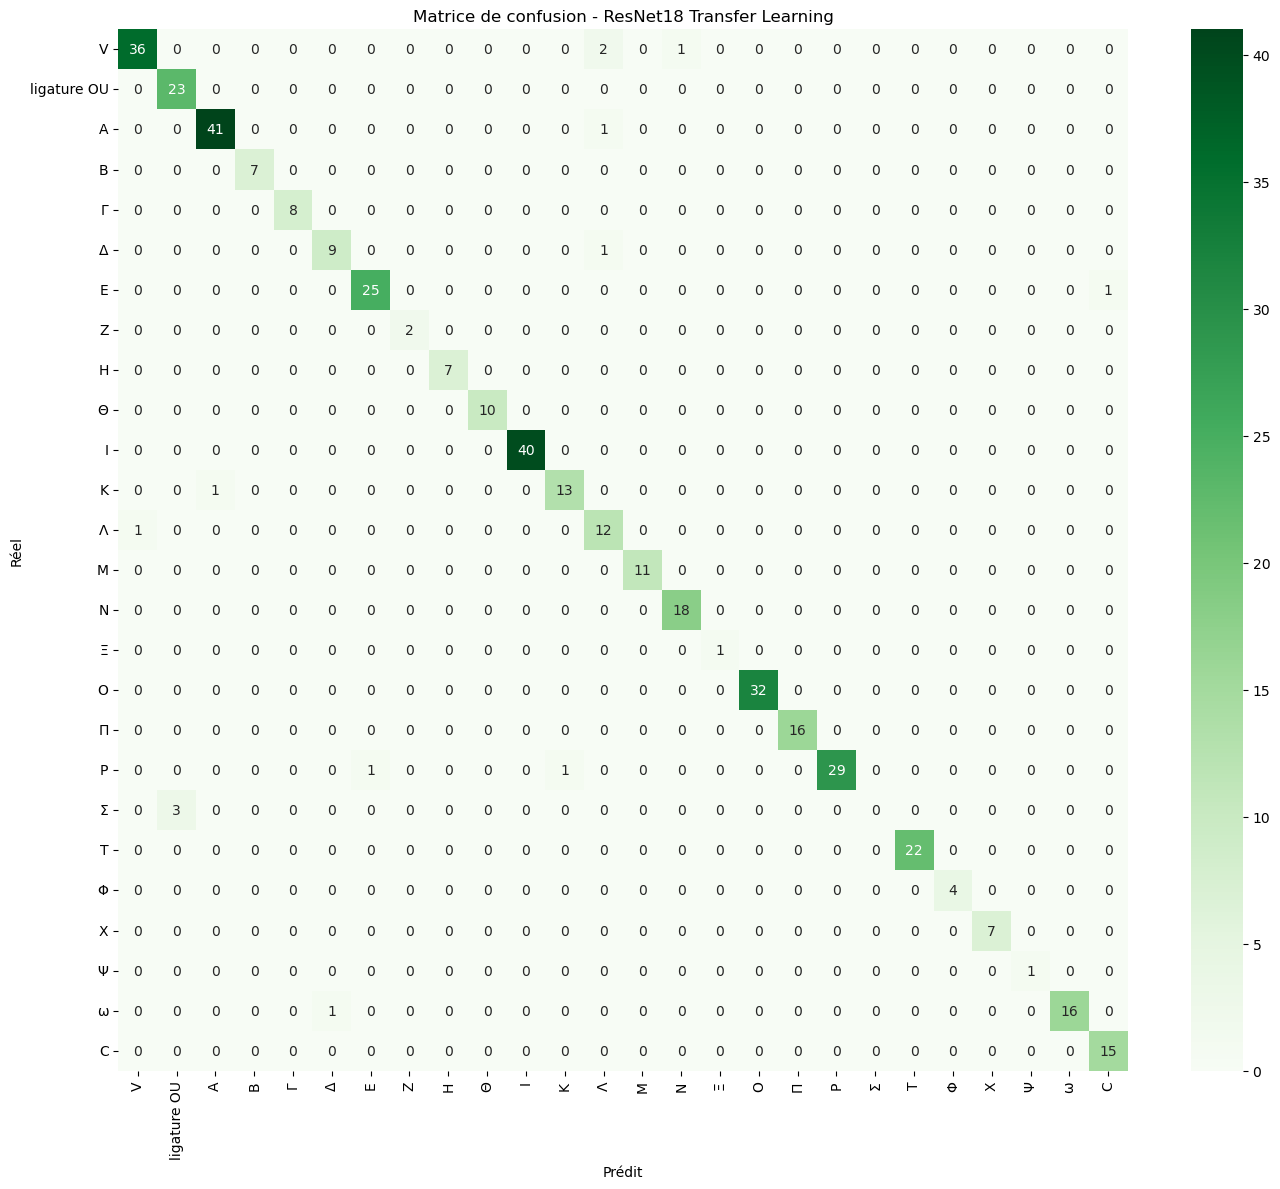


Résultats sauvegardés dans results_resnet.json


In [17]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title('Matrice de confusion - ResNet18 Transfer Learning')
plt.tight_layout()
plt.show()

# Sauvegarder les résultats
results = {
    "model": "ResNet18 Transfer Learning",
    "best_test_accuracy": best_test_acc,
    "final_test_accuracy": acc,
    "num_classes": num_classes,
    "num_epochs": NUM_EPOCHS,
    "classification_report": classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
}

with open("results_resnet.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("\nRésultats sauvegardés dans results_resnet.json")

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Installer timm si pas déjà fait
# !pip install timm
import timm

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"
IMG_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "train"), transform=train_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_dataset.classes
num_classes = len(class_names)

# ViT-Tiny avec transfer learning
model_vit = timm.create_model("vit_tiny_patch16_224", pretrained=True, num_classes=num_classes)
model_vit = model_vit.to(device)

total_params = sum(p.numel() for p in model_vit.parameters())
trainable_params = sum(p.numel() for p in model_vit.parameters() if p.requires_grad)
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")

NUM_EPOCHS = 40
LEARNING_RATE = 0.0001  # Plus petit pour ViT

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_vit.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

history_vit = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
best_test_acc_vit = 0.0

for epoch in range(NUM_EPOCHS):
    model_vit.train()
    train_loss, train_correct, train_total = 0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_vit(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    model_vit.eval()
    test_loss, test_correct, test_total = 0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_vit(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            test_correct += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_loss /= test_total
    test_acc = test_correct / test_total
    scheduler.step(test_loss)

    if test_acc > best_test_acc_vit:
        best_test_acc_vit = test_acc
        torch.save(model_vit.state_dict(), "best_vit_model.pth")

    history_vit["train_loss"].append(train_loss)
    history_vit["train_acc"].append(train_acc)
    history_vit["test_loss"].append(test_loss)
    history_vit["test_acc"].append(test_acc)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}")

print(f"\nMeilleure accuracy test ViT-Tiny: {best_test_acc_vit:.4f}")

Total params: 5,529,434
Trainable params: 5,529,434 (100.0%)
Epoch [5/40] Train Loss: 0.1439 Acc: 0.9623 | Test Loss: 0.2845 Acc: 0.9427
Epoch [10/40] Train Loss: 0.1253 Acc: 0.9640 | Test Loss: 0.2465 Acc: 0.9451
Epoch [15/40] Train Loss: 0.1093 Acc: 0.9687 | Test Loss: 0.2491 Acc: 0.9499
Epoch [20/40] Train Loss: 0.0831 Acc: 0.9756 | Test Loss: 0.2395 Acc: 0.9570
Epoch [25/40] Train Loss: 0.0666 Acc: 0.9797 | Test Loss: 0.2655 Acc: 0.9451
Epoch [30/40] Train Loss: 0.0584 Acc: 0.9768 | Test Loss: 0.2521 Acc: 0.9618
Epoch [35/40] Train Loss: 0.0478 Acc: 0.9826 | Test Loss: 0.2506 Acc: 0.9570
Epoch [40/40] Train Loss: 0.0419 Acc: 0.9849 | Test Loss: 0.2521 Acc: 0.9642

Meilleure accuracy test ViT-Tiny: 0.9666


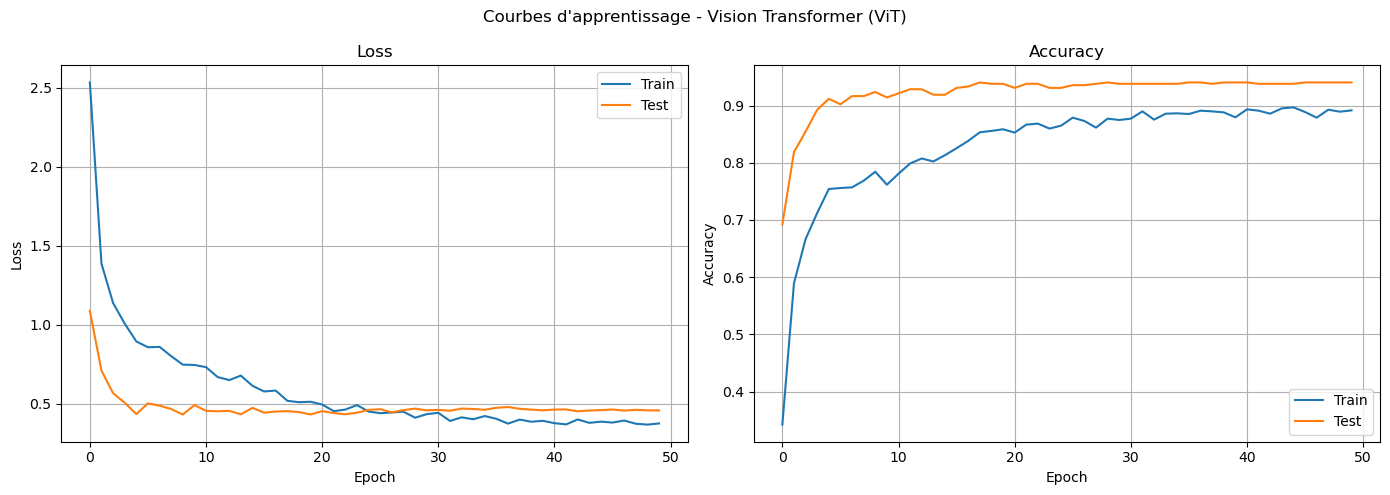

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["test_loss"], label="Test")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

ax2.plot(history["train_acc"], label="Train")
ax2.plot(history["test_acc"], label="Test")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True)

plt.suptitle("Courbes d'apprentissage - Vision Transformer (ViT)")
plt.tight_layout()
plt.show()

In [22]:
import timm

# Recrée EXACTEMENT le même modèle qu'à l'entraînement
model = timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=num_classes)
model = model.to(device)

# Charge les poids sauvegardés
model.load_state_dict(torch.load("best_vit_model.pth", map_location=device))
model.eval()

all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("=" * 60)
print("RAPPORT DE CLASSIFICATION - VISION TRANSFORMER (ViT)")
print("=" * 60)
print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))
acc = accuracy_score(all_labels, all_preds)
print(f"Accuracy globale: {acc:.4f} ({acc*100:.1f}%)")

RAPPORT DE CLASSIFICATION - VISION TRANSFORMER (ViT)
              precision    recall  f1-score   support

           V       1.00      0.92      0.96        39
 ligature OU       0.92      0.96      0.94        23
           Α       0.93      0.98      0.95        42
           Β       1.00      1.00      1.00         7
           Γ       1.00      1.00      1.00         8
           Δ       0.90      0.90      0.90        10
           Ε       0.93      0.96      0.94        26
           Ζ       1.00      1.00      1.00         2
           Η       1.00      1.00      1.00         7
           Θ       1.00      1.00      1.00        10
           Ι       1.00      1.00      1.00        40
           Κ       1.00      0.93      0.96        14
           Λ       0.87      1.00      0.93        13
           Μ       1.00      1.00      1.00        11
           Ν       0.95      1.00      0.97        18
           Ξ       1.00      1.00      1.00         1
           Ο       0.97     

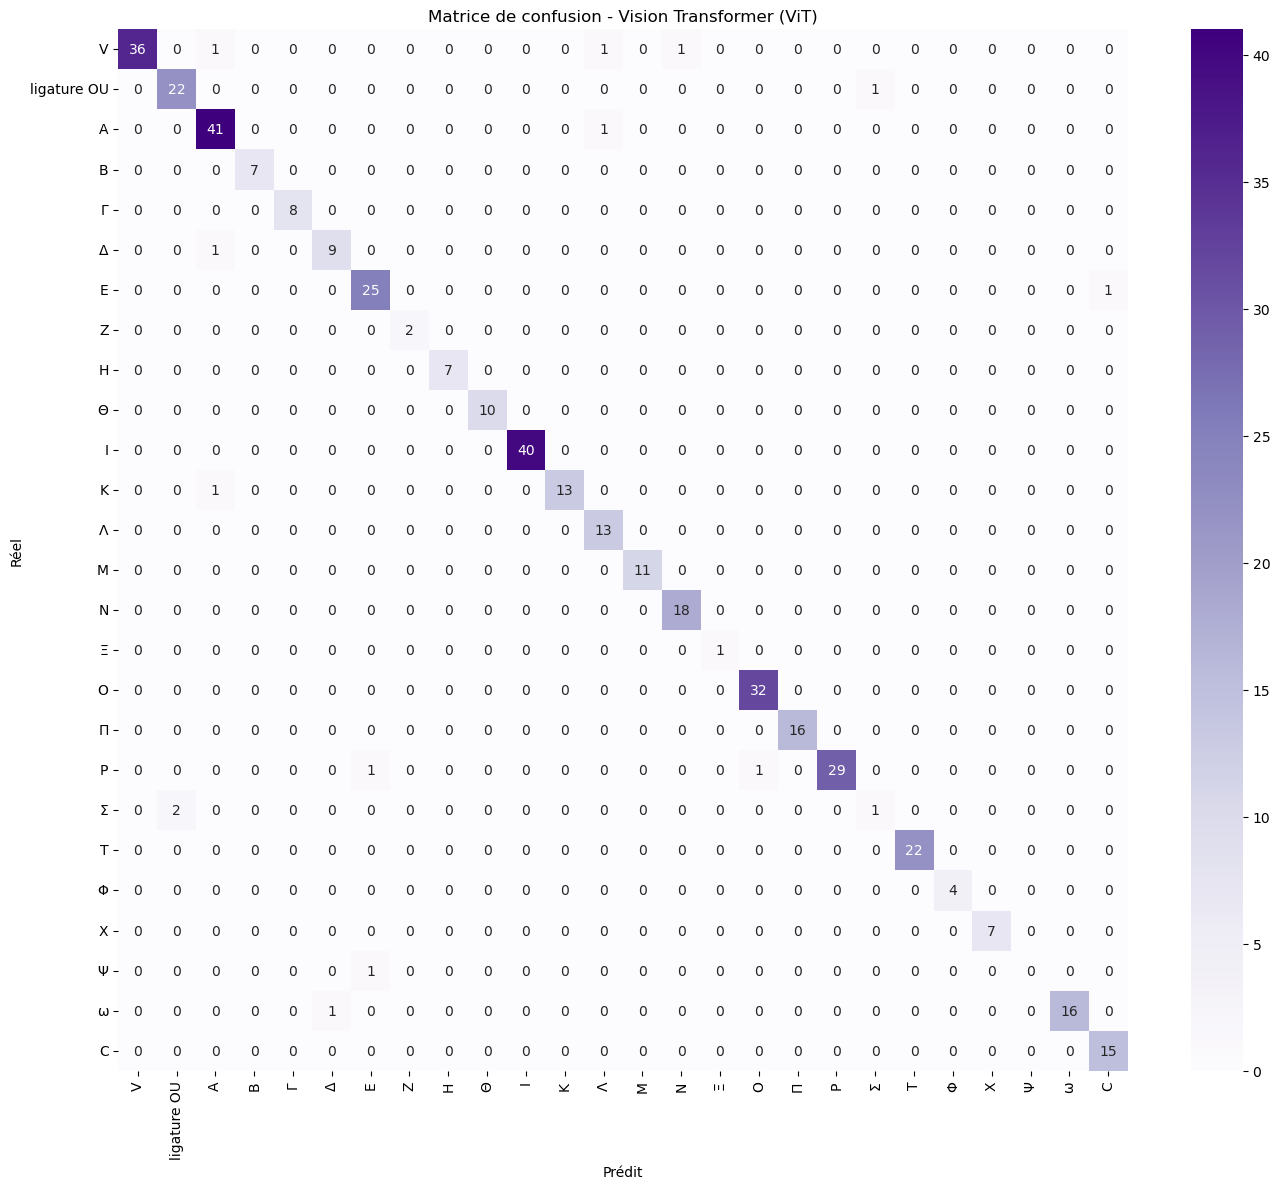


Résultats sauvegardés dans results_vit.json


In [23]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title('Matrice de confusion - Vision Transformer (ViT)')
plt.tight_layout()
plt.show()

# Sauvegarder les résultats
results = {
    "model": "Vision Transformer (ViT-Tiny)",
    "best_test_accuracy": best_test_acc,
    "final_test_accuracy": acc,
    "num_classes": num_classes,
    "num_epochs": NUM_EPOCHS,
    "classification_report": classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
}

with open("results_vit.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("\nRésultats sauvegardés dans results_vit.json")

✓ CNN sauvegardé: 0.9403
✓ ResNet sauvegardé: 0.9666
✓ ViT sauvegardé: 0.9666


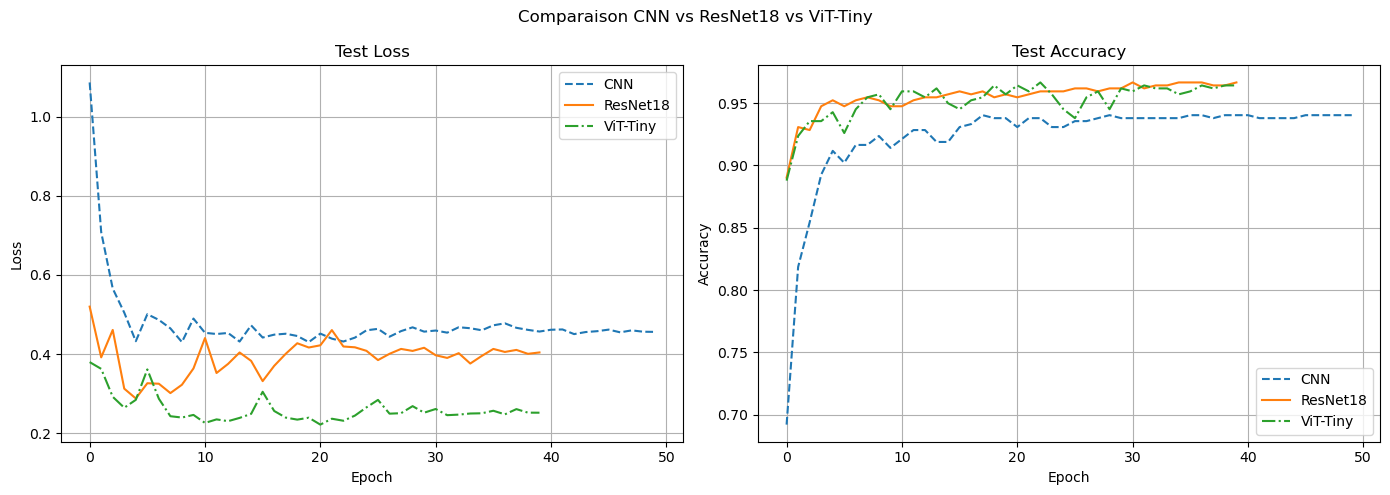


COMPARAISON FINALE
Modèle         Best Acc  Final Acc
-----------------------------------
CNN              0.9403     0.9403
ResNet18         0.9666     0.9666
ViT-Tiny         0.9666     0.9666


In [27]:
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

matplotlib.rcParams['font.family'] = 'DejaVu Sans'

# ============================================================
# 1. ÉVALUATION ET SAUVEGARDE CNN
# ============================================================

# Recharger le bon test_loader CNN (grayscale, 64x64)
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

SPLIT_DIR = r"C:\Users\sawad\Downloads\jeux\split"

test_transform_cnn = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

test_dataset_cnn = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform_cnn)
test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=16, shuffle=False)
class_names = test_dataset_cnn.classes
num_classes = len(class_names)

# Recréer le modèle CNN
model_cnn = SimpleCNN(num_classes).to(device)
model_cnn.load_state_dict(torch.load("best_cnn_model.pth"))
model_cnn.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader_cnn:
        images = images.to(device)
        outputs = model_cnn(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

acc_cnn = accuracy_score(all_labels, all_preds)
results_cnn = {
    "model": "CNN Simple",
    "best_test_accuracy": 0.9403,
    "final_test_accuracy": acc_cnn,
    "num_classes": num_classes,
    "history": history,
    "classification_report": classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
}
with open("results_cnn.json", "w", encoding="utf-8") as f:
    json.dump(results_cnn, f, ensure_ascii=False, indent=2)
print(f"✓ CNN sauvegardé: {acc_cnn:.4f}")

# ============================================================
# 2. ÉVALUATION ET SAUVEGARDE RESNET
# ============================================================

test_transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_dataset_resnet = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform_resnet)
test_loader_resnet = DataLoader(test_dataset_resnet, batch_size=16, shuffle=False)

from torchvision import models
model_resnet = models.resnet18(weights=None)
num_features = model_resnet.fc.in_features
model_resnet.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),
    torch.nn.Linear(num_features, 256),
    torch.nn.ReLU(),
    torch.nn.Dropout(0.3),
    torch.nn.Linear(256, num_classes)
)
model_resnet.load_state_dict(torch.load("best_resnet_model.pth"))
model_resnet = model_resnet.to(device)
model_resnet.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader_resnet:
        images = images.to(device)
        outputs = model_resnet(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

acc_resnet = accuracy_score(all_labels, all_preds)
results_resnet = {
    "model": "ResNet18",
    "best_test_accuracy": 0.9666,
    "final_test_accuracy": acc_resnet,
    "num_classes": num_classes,
    "history": history_resnet,
    "classification_report": classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
}
with open("results_resnet.json", "w", encoding="utf-8") as f:
    json.dump(results_resnet, f, ensure_ascii=False, indent=2)
print(f"✓ ResNet sauvegardé: {acc_resnet:.4f}")

# ============================================================
# 3. ÉVALUATION ET SAUVEGARDE VIT
# ============================================================

test_dataset_vit = datasets.ImageFolder(root=os.path.join(SPLIT_DIR, "test"), transform=test_transform_resnet)
test_loader_vit = DataLoader(test_dataset_vit, batch_size=16, shuffle=False)

import timm
model_vit = timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=num_classes)
model_vit.load_state_dict(torch.load("best_vit_model.pth"))
model_vit = model_vit.to(device)
model_vit.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader_vit:
        images = images.to(device)
        outputs = model_vit(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

acc_vit = accuracy_score(all_labels, all_preds)
results_vit = {
    "model": "ViT-Tiny",
    "best_test_accuracy": 0.9666,
    "final_test_accuracy": acc_vit,
    "num_classes": num_classes,
    "history": history_vit,
    "classification_report": classification_report(all_labels, all_preds, target_names=class_names, output_dict=True, zero_division=0)
}
with open("results_vit.json", "w", encoding="utf-8") as f:
    json.dump(results_vit, f, ensure_ascii=False, indent=2)
print(f"✓ ViT sauvegardé: {acc_vit:.4f}")

# ============================================================
# 4. GRAPHIQUES DE COMPARAISON
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Courbes de loss
axes[0].plot(history["test_loss"], label="CNN", linestyle="--")
axes[0].plot(history_resnet["test_loss"], label="ResNet18", linestyle="-")
axes[0].plot(history_vit["test_loss"], label="ViT-Tiny", linestyle="-.")
axes[0].set_title("Test Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Courbes d'accuracy
axes[1].plot(history["test_acc"], label="CNN", linestyle="--")
axes[1].plot(history_resnet["test_acc"], label="ResNet18", linestyle="-")
axes[1].plot(history_vit["test_acc"], label="ViT-Tiny", linestyle="-.")
axes[1].set_title("Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("Comparaison CNN vs ResNet18 vs ViT-Tiny")
plt.tight_layout()
plt.savefig("comparaison_modeles.png", dpi=150)
plt.show()

# ============================================================
# 5. TABLEAU RÉCAPITULATIF
# ============================================================

print("\n" + "=" * 60)
print("COMPARAISON FINALE")
print("=" * 60)
print(f"{'Modèle':<12} {'Best Acc':>10} {'Final Acc':>10}")
print("-" * 35)
print(f"{'CNN':<12} {0.9403:>10.4f} {acc_cnn:>10.4f}")
print(f"{'ResNet18':<12} {0.9666:>10.4f} {acc_resnet:>10.4f}")
print(f"{'ViT-Tiny':<12} {0.9666:>10.4f} {acc_vit:>10.4f}")

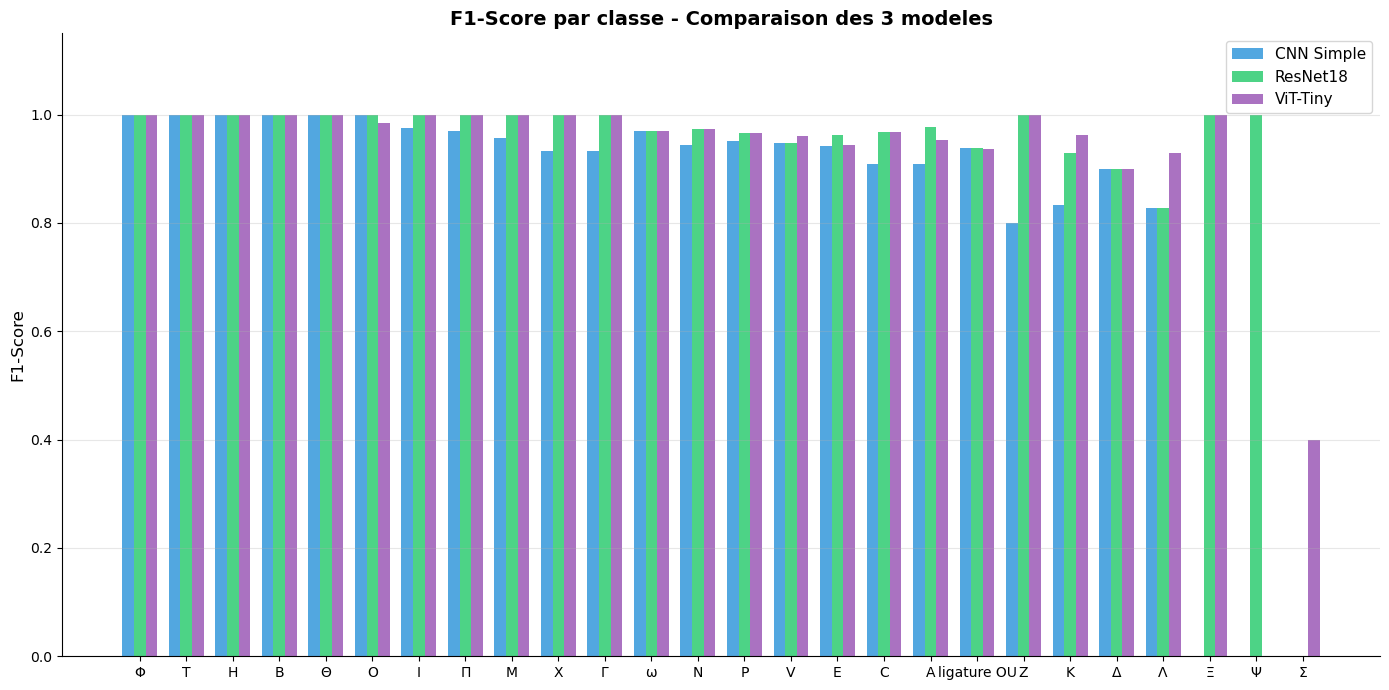

In [28]:
classes = []
for key in cnn_results['classification_report']:
    if key not in ['accuracy', 'macro avg', 'weighted avg']:
        classes.append(key)

f1_cnn = [cnn_results['classification_report'].get(c, {}).get('f1-score', 0) for c in classes]
f1_resnet = [resnet_results['classification_report'].get(c, {}).get('f1-score', 0) for c in classes]
f1_vit = [vit_results['classification_report'].get(c, {}).get('f1-score', 0) for c in classes]

avg_f1 = [(f1_cnn[i] + f1_resnet[i] + f1_vit[i]) / 3 for i in range(len(classes))]
sorted_indices = np.argsort(avg_f1)[::-1]
classes_sorted = [classes[i] for i in sorted_indices]
f1_cnn_sorted = [f1_cnn[i] for i in sorted_indices]
f1_resnet_sorted = [f1_resnet[i] for i in sorted_indices]
f1_vit_sorted = [f1_vit[i] for i in sorted_indices]

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(classes_sorted))
width = 0.25

ax.bar(x - width, f1_cnn_sorted, width, label='CNN Simple', color='#3498db', alpha=0.85)
ax.bar(x, f1_resnet_sorted, width, label='ResNet18', color='#2ecc71', alpha=0.85)
ax.bar(x + width, f1_vit_sorted, width, label='ViT-Tiny', color='#9b59b6', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(classes_sorted, fontsize=10)
ax.set_ylabel('F1-Score', fontsize=12)
ax.set_title('F1-Score par classe - Comparaison des 3 modeles', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0, 1.15)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('comparaison_f1_par_classe.png', dpi=150, bbox_inches='tight')
plt.show()

CNN:    0.9403
ResNet: 0.9666
ViT:    0.9666


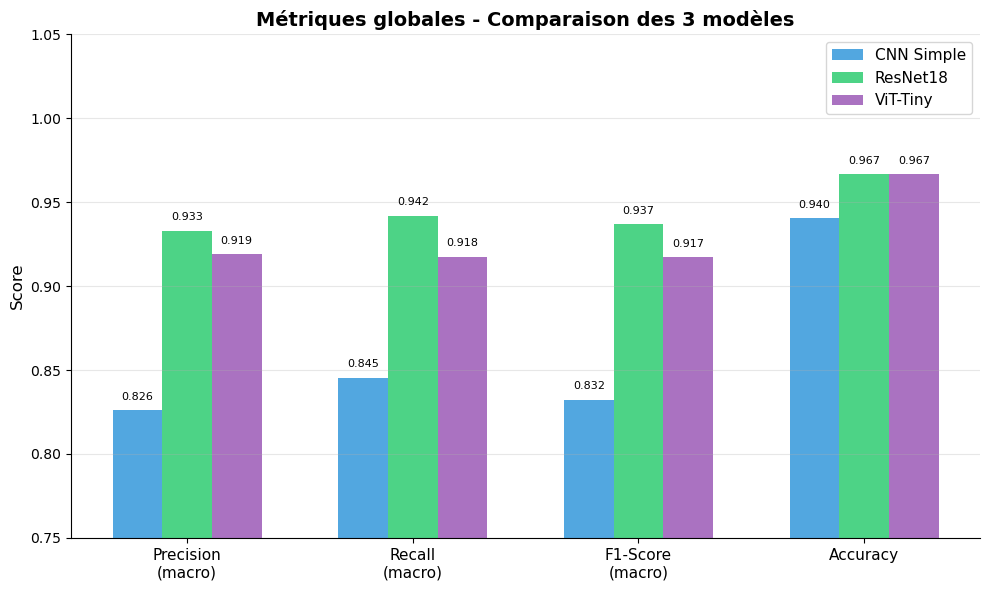

In [30]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

with open("results_cnn.json", "r", encoding="utf-8") as f:
    cnn_results = json.load(f)
with open("results_resnet.json", "r", encoding="utf-8") as f:
    resnet_results = json.load(f)
with open("results_vit.json", "r", encoding="utf-8") as f:
    vit_results = json.load(f)

print(f"CNN:    {cnn_results['final_test_accuracy']:.4f}")
print(f"ResNet: {resnet_results['final_test_accuracy']:.4f}")
print(f"ViT:    {vit_results['final_test_accuracy']:.4f}")

metrics = ['Precision\n(macro)', 'Recall\n(macro)', 'F1-Score\n(macro)', 'Accuracy']

cnn_metrics = [
    cnn_results['classification_report']['macro avg']['precision'],
    cnn_results['classification_report']['macro avg']['recall'],
    cnn_results['classification_report']['macro avg']['f1-score'],
    cnn_results['final_test_accuracy']
]
resnet_metrics = [
    resnet_results['classification_report']['macro avg']['precision'],
    resnet_results['classification_report']['macro avg']['recall'],
    resnet_results['classification_report']['macro avg']['f1-score'],
    resnet_results['final_test_accuracy']
]
vit_metrics = [
    vit_results['classification_report']['macro avg']['precision'],
    vit_results['classification_report']['macro avg']['recall'],
    vit_results['classification_report']['macro avg']['f1-score'],
    vit_results['final_test_accuracy']
]

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(metrics))
width = 0.22

bars1 = ax.bar(x - width, cnn_metrics, width, label='CNN Simple', color='#3498db', alpha=0.85)
bars2 = ax.bar(x, resnet_metrics, width, label='ResNet18', color='#2ecc71', alpha=0.85)
bars3 = ax.bar(x + width, vit_metrics, width, label='ViT-Tiny', color='#9b59b6', alpha=0.85)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.005,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Métriques globales - Comparaison des 3 modèles', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0.75, 1.05)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('comparaison_metriques_globales.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
# Ajouter les champs manquants
cnn_results['num_epochs'] = 50
resnet_results['num_epochs'] = 40
vit_results['num_epochs'] = 40

# Corriger aussi best_test_accuracy avec les vraies valeurs
cnn_results['best_test_accuracy'] = cnn_results['final_test_accuracy']
resnet_results['best_test_accuracy'] = resnet_results['final_test_accuracy']
vit_results['best_test_accuracy'] = vit_results['final_test_accuracy']

classes = cnn_results['classification_report'].keys()
classes = [c for c in classes if c not in ['accuracy', 'macro avg', 'weighted avg']]

print("=" * 75)
print("TABLEAU RECAPITULATIF")
print("=" * 75)
print(f"{'Metrique':<25} {'CNN Simple':>12} {'ResNet18':>12} {'ViT-Tiny':>12}")
print("-" * 75)
print(f"{'Accuracy':<25} {cnn_results['best_test_accuracy']:>11.4f} {resnet_results['best_test_accuracy']:>12.4f} {vit_results['best_test_accuracy']:>12.4f}")
print(f"{'Precision (macro)':<25} {cnn_results['classification_report']['macro avg']['precision']:>11.4f} {resnet_results['classification_report']['macro avg']['precision']:>12.4f} {vit_results['classification_report']['macro avg']['precision']:>12.4f}")
print(f"{'Recall (macro)':<25} {cnn_results['classification_report']['macro avg']['recall']:>11.4f} {resnet_results['classification_report']['macro avg']['recall']:>12.4f} {vit_results['classification_report']['macro avg']['recall']:>12.4f}")
print(f"{'F1-Score (macro)':<25} {cnn_results['classification_report']['macro avg']['f1-score']:>11.4f} {resnet_results['classification_report']['macro avg']['f1-score']:>12.4f} {vit_results['classification_report']['macro avg']['f1-score']:>12.4f}")
print(f"{'F1-Score (weighted)':<25} {cnn_results['classification_report']['weighted avg']['f1-score']:>11.4f} {resnet_results['classification_report']['weighted avg']['f1-score']:>12.4f} {vit_results['classification_report']['weighted avg']['f1-score']:>12.4f}")
print(f"{'Epochs':<25} {cnn_results['num_epochs']:>11} {resnet_results['num_epochs']:>12} {vit_results['num_epochs']:>12}")
print("-" * 75)
print(f"{'MEILLEUR MODELE':<25} -> ResNet18 Transfer Learning")
print("=" * 75)
print("\nCLASSES PROBLEMATIQUES (F1 < 0.8) :")
print("-" * 75)
for c in classes:
    f1s = {
        'CNN': cnn_results['classification_report'].get(c, {}).get('f1-score', 0),
        'ResNet': resnet_results['classification_report'].get(c, {}).get('f1-score', 0),
        'ViT': vit_results['classification_report'].get(c, {}).get('f1-score', 0)
    }
    if any(v < 0.8 for v in f1s.values()):
        support = cnn_results['classification_report'].get(c, {}).get('support', 0)
        print(f"  {c} (support={int(support)}): CNN={f1s['CNN']:.2f} | ResNet={f1s['ResNet']:.2f} | ViT={f1s['ViT']:.2f}")
print("\nGraphiques sauvegardes :")
print("  - comparaison_accuracy.png")
print("  - comparaison_f1_par_classe.png")
print("  - comparaison_metriques_globales.png")
print("  - comparaison_radar.png")

TABLEAU RECAPITULATIF
Metrique                    CNN Simple     ResNet18     ViT-Tiny
---------------------------------------------------------------------------
Accuracy                       0.9403       0.9666       0.9666
Precision (macro)              0.8262       0.9330       0.9191
Recall (macro)                 0.8455       0.9419       0.9175
F1-Score (macro)               0.8323       0.9368       0.9172
F1-Score (weighted)            0.9351       0.9637       0.9649
Epochs                             50           40           40
---------------------------------------------------------------------------
MEILLEUR MODELE           -> ResNet18 Transfer Learning

CLASSES PROBLEMATIQUES (F1 < 0.8) :
---------------------------------------------------------------------------
  Ξ (support=1): CNN=0.00 | ResNet=1.00 | ViT=1.00
  Σ (support=3): CNN=0.00 | ResNet=0.00 | ViT=0.40
  Ψ (support=1): CNN=0.00 | ResNet=1.00 | ViT=0.00

Graphiques sauvegardes :
  - comparaison_accuracy.png
